# 🎓 종합 실습 — 소득세법 멀티 RAG 챗봇




## 오늘 만들 것

```
 사용자 질문
     │
     ▼
 [라우터]  ─┬─ 계산 질문 ─▶ 🧮 계산봇 (세금 계산)
            ├─ 법령 질문 ─▶ 📖 법령봇 (소득세법 RAG)
            └─ 잡담 ──────▶ 💬 상담봇
```

실제 소득세법 문서를 검색하는 **멀티 챗봇**을 만듭니다.
RAG·LangGraph·라우팅을 모두 통합합니다.

## 7단계 프로세스 

| 단계 | 무엇 | 
|------|------|----------|  
| 1️⃣ | 준비 (설치·키) |  
| 2️⃣ | 데이터 (PDF 로드·분할) |  
| 3️⃣ | 검색 준비 (임베딩·벡터DB) |  
| 4️⃣ | 단순 RAG (베이스라인) |  
| 5️⃣ | 한계 측정 + 3개 봇 |  
| 6️⃣ | LangGraph 라우팅 |  
| 7️⃣ | 기본 vs 완성 비교 |  


---
## 📝 이 노트북은 "빈칸 채우기 워크북"입니다

```
 ┌──────────────────────────────────────────┐
 │  ____ (밑줄 4개)를 직접 코딩해 채우세요   │
 │  각 빈칸 위에 # ✍️ 힌트 주석이 있습니다   │
 └──────────────────────────────────────────┘
```

**진행 방법**
1. 셀을 위에서부터 순서대로 봅니다
2. `# 📌 [그대로 실행]` 셀은 그냥 실행 (설치·키 등)
3. `# ✍️ [빈칸 채우기]` 셀은 `____` 를 **직접 작성**
4. 바로 위 `힌트:` 주석을 보고 무엇을 넣을지 생각
5. 실행해서 ✅ 출력이 나오면 성공, 안 되면 힌트 다시 읽기

**채워야 할 빈칸**: 총 24개 (14개 셀)
- 보일러플레이트(설치·import·키)는 빈칸 없음 — 그대로 실행
- 핵심 학습 코드(RAG·계산봇·라우터·LangGraph·Gradio)만 빈칸


> 💡 복붙하지 말고 **손으로 타이핑**하세요. 그래야 남습니다.
> 빈칸은 대부분 메서드 이름(`.invoke`, `.from_documents`)이나
> 모델명("gpt-4o-mini") 한 단어입니다. 어렵지 않습니다.
---

# 1️⃣ 단계 — 준비 (설치 + 키)

### 셀 1 — 설치

In [1]:
!pip install -q langchain langchain-openai langchain-community \
    langchain-text-splitters langgraph pypdf faiss-cpu
print("✅ 설치 완료")

✅ 설치 완료



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


**이 셀이 한 일**: 필요한 패키지를 설치했습니다.
(벡터DB는 FAISS 하나로 통일 — 추가 설치 불필요)

### 셀 2 — OpenAI 키

In [64]:
# 📌 [그대로 실행] OpenAI 키 등록
#   - Colab 왼쪽 🔑 아이콘에 OPENAI_API_KEY 등록 권장
import os
# from dotenv import load_dotenv
# load_dotenv

try:
    from google.colab import userdata
    os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
except Exception:
    from dotenv import load_dotenv
    load_dotenv(".env", override=True)

print("✅ 키 준비됨" if os.environ.get("OPENAI_API_KEY") else "❌ 키 확인 필요")

✅ 키 준비됨


**이 셀이 한 일**: OpenAI 키를 등록했습니다.

### 셀 3 — 모델 준비

In [66]:
# ✍️ [빈칸 채우기] 답변용 LLM + 검색용 임베딩 만들기
#   힌트: 답변 모델 "gpt-4o-mini", 임베딩 "text-embedding-3-small"
from langchain_openai import ChatOpenAI, OpenAIEmbeddings

# (1) 답변용 LLM — temperature=0 (일관된 답)
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

# (2) 검색용 임베딩 모델
embeddings = OpenAIEmbeddings(model='text_embedding-3-small')

print("✅ LLM + 임베딩 준비 완료")

✅ LLM + 임베딩 준비 완료


---

# 2️⃣ 단계 — 데이터 (소득세법 PDF 로드·분할)

실제 소득세법 PDF를 불러와 조문 단위로 나눕니다.

### 셀 4 — PDF 업로드

In [67]:
PDF = "content/소득세법_실습데이터.pdf"
print(f"✅ 업로드: {PDF}")
#=======================================
# # 구글 colab에 여러개의 파일을 업로드 할 수 있도록 구현하세요.
# from google.colab import files

# up = files.upload()     #실행 시 파일 선택장 -> PDF 고르기 {파일이름; 파일내용(bytes)}
# PDF = next(k for k in up if k.lower().endwsith(".pdf")) # 가지고 있는 모든 파일을 소문자화해서 파일을 찾는다. .pdf를 불러와 PDF에 담는다.

✅ 업로드: content/소득세법_실습데이터.pdf


**이 셀이 한 일**: 소득세법 PDF를 PDF라는 변수에 담았습니다.

### 셀 5 — 텍스트 추출

In [68]:
# ✍️ [빈칸 채우기] PDF 텍스트 추출 + 본문 시작점 찾기
import pypdf, re    #re: 정규표현식, 레귤러익스프레션.

reader = pypdf.PdfReader(PDF)   # PDF를 컴퓨터가 읽을 수 있도록 열어라.
# (1) 모든 페이지 텍스트 추출 — 힌트: 페이지의 .extract_text()
#reader로 읽어온 PDF파일을 페이지로 돌면서 text를 추출해 list로 모으겠다.
# -> 리스트 커프리헨션으로 
pages =[(p.extract_text() or "") for p in reader.pages]
full = "\n".join(pages)
print(f"총 페이지 수{len(pages)}\n\n")
print(f"추출 텍스트 {len(full)}")
print(full[:200],"\n\n\n")
# (2) 본문 시작 = "제1조(목적)" 위치 (앞 목차 건너뛰기)
#     힌트: 정규식 패턴 "제1\\s?조\\(목적\\)"
m = re.search(r"제1\s?조\(목적\)\s*이\s?법은", full) # s?: 공백이 있어도 되고 없어도 되고 / '\\('와')\\'는 쌍
body = full[m.start():] if m else full
# 패턴을 찾았으면 지정 위치부터 끝가지를 본분으로, 못찾으면 전체 사용하겠다(안전장치다.)
print(f"본문 시작 위치: {m.start() if m else 0}")
print("---본문 미리보기---")
print(body[:500])
print(f"본문미리보기완료")
print(f"✅ {len(reader.pages)}페이지에서 {len(body):,}자 추출")
print(body[:150])

총 페이지 수179


추출 텍스트 282463
소득세법
소득세법
[  시행2026. 4. 21.] [  법률제21548호, 2026. 4. 21., 일부개정]
       제1  장총칙
             제1 조(목적)
             제1 조의2(정의)
             제2 조(납세의무)
             제2 조의2(  납세의무의범위)
             제2 조의3(  



본문 시작 위치: 14603
---본문 미리보기---
제1 조(목적)               이법은개인의소득에대하여소득의성격과납세자의부담능력등에따라적정하게과세함으로써조세부담의
       형평을도모하고재정수입의원활한조달에이바지함을목적으로한다 .
[  본조신설2009. 12. 31.]
[  종전제1  조는제2   조로이동 <2009. 12. 31.>]
제1 조의2(정의) ①       이법에서사용하는용어의뜻은다음과같다 . <  개정2010. 12. 27., 2014. 12. 23., 2018. 12. 
31.>
1. “ ”     거주자란국내에주소를두거나 183   일이상의거소 (居所)    를둔개인을말한다 .
2. “ ”     비거주자란거주자가아닌개인을말한다 .
3. “ ”   내국법인이란「법인세법」제 2조제1    호에따른내국법인을말한다 .
4. “ ”   외국법인이란「법인세법」제 2조제3    호에따른외국법인을말한다 .
5. “ ”     사업자란사업소득이있는거주자를말한다 .
② 제1       항에따른주소ㆍ거소와거주자ㆍ비거주자
본문미리보기완료
✅ 179페이지에서 267,860자 추출
제1 조(목적)               이법은개인의소득에대하여소득의성격과납세자의부담능력등에따라적정하게과세함으로써조세부담의
       형평을도모하고재정수입의원활한조달에이바지함을목적으로한다 .
[  본조신설2009. 12. 31.]
[  종전제1  조는제2   조로이동


**이 셀이 한 일**: PDF에서 텍스트를 추출하고,
앞쪽 목차를 건너뛰어 본문만 남겼습니다.

### 셀 6 — 조문 단위로 분할

법령은 "제○조" 단위로 나누는 게 자연스럽습니다.
(조문 = 의미 있는 단위)

In [69]:
import re
pat = re.compile(r"(제\s?\d+\s?조(?:\s?의\s?\d+)?)\s*\(\s*([^)]+?)\s*\)")
print(pat)
print()
for text in ["제55조(세율)","제 55 조 ( 세율)","제22조의2(퇴직소득)"]:
    m = pat.search(text)
    print(m)
    print(f"{text:20}->",(m.group(1),m.group(2))if m else "매칭없음")
    print()

re.compile('(제\\s?\\d+\\s?조(?:\\s?의\\s?\\d+)?)\\s*\\(\\s*([^)]+?)\\s*\\)')

<re.Match object; span=(0, 8), match='제55조(세율)'>
제55조(세율)            -> ('제55조', '세율')

<re.Match object; span=(0, 12), match='제 55 조 ( 세율)'>
제 55 조 ( 세율)        -> ('제 55 조', '세율')

<re.Match object; span=(0, 12), match='제22조의2(퇴직소득)'>
제22조의2(퇴직소득)        -> ('제22조의2', '퇴직소득')



In [70]:
# ✍️ [빈칸 채우기] 본문을 "제○조" 단위 분할 + 메타데이터
from langchain_core.documents import Document

pat = re.compile(r"(제\s?\d+\s?조(?:\s?의\s?\d+)?)\s*\(\s*([^)]+?)\s*\)")
matches = list(pat.finditer(body))

docs = []   # 완성된 조문 문서를 담을 리스트
for i, mt in enumerate(matches):
    jo = re.sub(r"\s+", "", mt.group(1))      # 제50조
    title = re.sub(r"\s+", "", mt.group(2))   # 기본공제
    start = mt.start()
    end = matches[i+1].start() if i+1 < len(matches) else len(body)
    content = body[start:end].strip()
    if len(content) < 15:       # 짧으면 목차 → 제외
        continue
    # Document 만들기 — 힌트: page_content=본문[:1500],
    #   metadata={"조": jo, "제목": title}
    docs.append(Document(
        page_content=content[:1500],
        metadata={"조": jo,"제목": title}))
q =len(docs)
print(f"✅ 조문 {q}개로 분할")
print(f"예시: {docs[0].metadata}\n\n")
for i in range(q):    
    print(f"예시: {docs[i].metadata}")

✅ 조문 285개로 분할
예시: {'조': '제1조', '제목': '목적'}


예시: {'조': '제1조', '제목': '목적'}
예시: {'조': '제1조의2', '제목': '정의'}
예시: {'조': '제2조', '제목': '납세의무'}
예시: {'조': '제2조의2', '제목': '납세의무의범위'}
예시: {'조': '제2조의3', '제목': '신탁재산귀속소득에대한납세의무의범위'}
예시: {'조': '제3조', '제목': '과세소득의범위'}
예시: {'조': '제4조', '제목': '소득의구분'}
예시: {'조': '제5조', '제목': '과세기간'}
예시: {'조': '제6조', '제목': '납세지'}
예시: {'조': '제7조', '제목': '원천징수등의경우의납세지'}
예시: {'조': '제8조', '제목': '상속등의경우의납세지'}
예시: {'조': '제9조', '제목': '납세지의지정'}
예시: {'조': '제10조', '제목': '납세지의변경신고'}
예시: {'조': '제11조', '제목': '과세관할'}
예시: {'조': '제12조', '제목': '비과세소득'}
예시: {'조': '제14조', '제목': '과세표준의계산'}
예시: {'조': '제15조', '제목': '세액계산의순서'}
예시: {'조': '제16조', '제목': '이자소득'}
예시: {'조': '제17조', '제목': '배당소득'}
예시: {'조': '제17조', '제목': '배당소득'}
예시: {'조': '제19조', '제목': '사업소득'}
예시: {'조': '제20조', '제목': '근로소득'}
예시: {'조': '제20조의3', '제목': '연금소득'}
예시: {'조': '제21조', '제목': '기타소득'}
예시: {'조': '제21조', '제목': '기타소득'}
예시: {'조': '제22조', '제목': '퇴직소득'}
예시: {'조': '제24조', '제목': '총수입금액의계산'}
예시: {'조': '제25조', '제목': '총수입금액계산의특례'}
예시: {'조': 

**이 셀이 한 일**: 본문을 "제○조" 단위로 나누고,
각 조문에 조번호·제목을 메타데이터로 붙였습니다.

# 3️⃣ 단계 — 검색 준비 (임베딩 + FAISS)

조문들을 검색 가능한 벡터로 만들어 저장합니다.

### 셀 7 — 벡터DB + 검색기

### 만든셀. 다시 해보기.

In [71]:
from langchain_community.vectorstores import FAISS
from langchain_classic.text_splitter import RecursiveCharacterTextSplitter
from langchain_text_splitters import RecursiveCharacterTextSplitter


# 긴 조문을 약 500자로 한 번 더 잘라 검색 정확도를 높힌다.
splitter = RecursiveCharacterTextSplitter(
                chunk_size = 500,
                chunk_overlap =50,
                separators=["\nn","\n"," ",""]           #자르는 순서: 문단-> 줄->띄어쓰기->글자
)
chunks = splitter.split_documents(docs)

#2. 임베딩
emb = OpenAIEmbeddings(model = "text-embedding-3-small")
#3. FAISS
vs = FAISS.from_documents(chunks,emb)
#4. 검색시: 질문이 오면 가장 비슷한 조문 k개를 가지고 온다.
retriever = vs.as_retriever(search_kwrgs ={"k=3"})
print(f"청크 {len(chunks)} 개 임베딩 완료")
# 검증 — 만들고 바로 테스트(좋은 습관): '세율' 질문에 관련 조문이 나오나?
for d in retriever.invoke("종합소득세 세율"):
    print(f"  [{d.metadata.get('조')} {d.metadata.get('제목')}] "
          f"{d.page_content[:45]}...")
print("✅ 검색 동작 확인")

청크 588 개 임베딩 완료
  [제15조 세액계산의순서] 제15 조(   세액계산의순서 )              거주자의종합소득및퇴직소득...
  [제55조 세율] 제55 조(세율) ①            거주자의종합소득에대한소득세는해당연도의종합...
  [제129조 원천징수세율] 6.     기타소득에대해서는다음에규정하는세율 . 다만, 제8    호를적용받는경...
  [제129조 원천징수세율] 6.     기타소득에대해서는다음에규정하는세율 . 다만, 제8    호를적용받는경...
✅ 검색 동작 확인


### 기존7셀

In [61]:
# # ✍️ [빈칸 채우기] 조문 벡터 저장 + 검색기
# from langchain_community.vectorstores import FAISS

# # (1) docs를 임베딩해 FAISS에 — 힌트: FAISS.from_documents(docs, embeddings)
# vectordb = FAISS.from_documents(docs, emb)

# # (2) 검색기, 질문당 3개 — 힌트: as_retriever(search_kwargs={"k": 3})
# retriever = vectordb.as_retriever(search_kwargs={"k": 3})

# print("✅ 검색 준비 완료")
# print("질문 '기본공제' 검색 결과:")
# for d in retriever.invoke("기본공제는 얼마인가요?"):
#     print(f"  [{d.metadata['조']} {d.metadata['제목']}]")

**이 셀이 한 일**: 조문을 벡터로 저장하고
검색기(`retriever`)를 만들었습니다.

> 💡 "기본공제" 질문에 관련 조문이 나오면 성공 —
> 단어가 정확히 안 맞아도 의미로 찾습니다 (3교시).

---

### 🔄 [멀티모달 보완] 세율표 이미지를 비전으로 복원

> ⚠️ 문제 발견: 소득세법 **제55조 세율표는 PDF에 '이미지'로**
> 들어 있습니다 (p51). `pypdf` 텍스트 추출로는 **안 잡힙니다.**
> 그래서 "과세표준은 어떻게 돼?" 질문에 법령봇이 제대로
> 답하지 못하고, 계산봇도 세율을 모릅니다.

```
 [텍스트 추출만]              [멀티모달 보완]
 세율표 이미지 → 0글자        비전 모델이 표를 읽어
 "확인 안 됨" ❌               텍스트로 복원 → 색인 ✅
```

**해결**: 세율표 이미지 페이지를 찾아 비전 모델(GPT-4o)로
표를 텍스트로 복원 → 벡터DB에 추가. 

In [72]:
import base64
from langchain_core.messages import HumanMessage

# 1) 제55조 세율표가 있는 페이지 자동 탐색
import pdfplumber
rate_page = None
with pdfplumber.open(PDF) as pdf:
    for i, p in enumerate(pdf.pages):
        t = p.extract_text() or ""
        if "제55조(세율)" in t and "종합소득과세표준" in t:
            # 본문 다음 페이지에 표 이미지가 있음
            for cand in (i, i + 1):
                big = [im for im in pdf.pages[cand].images
                       if im["width"] > 200 and im["height"] > 100]
                if big:
                    rate_page = cand
                    break
        if rate_page is not None:
            break

print(f"✅ 세율표 이미지 페이지 발견: p{rate_page}")

# 2) 그 페이지를 고해상도 이미지로 저장
with pdfplumber.open(PDF) as pdf:
    pdf.pages[rate_page].to_image(resolution=300).save("rate_table.png")
print("✅ 세율표 페이지 캡처 완료 (rate_table.png)")

✅ 세율표 이미지 페이지 발견: p51
✅ 세율표 페이지 캡처 완료 (rate_table.png)


**이 셀이 한 일**: 제55조 세율표가 이미지로 있는
페이지(p51)를 자동으로 찾아 캡처했습니다.

In [73]:
# ✍️ [빈칸 채우기] 비전 모델로 세율표 이미지 → 텍스트(OCR)
#   ⚠️ 프롬프트를 "OCR 작업"으로! 세무 단어 많으면 거부됨
with open("rate_table.png", "rb") as f:
    img_b64 = base64.b64encode(f.read()).decode()

# (1) 비전 모델 — "gpt-4o" (mini 아님, 표 정확도)
vision = ChatOpenAI(model="gpt-4o", temperature=0)

vision_msg = HumanMessage(content=[
    {"type": "text", "text":
     "다음 이미지에 표가 하나 있습니다. OCR 작업입니다: "
     "표의 각 행과 열에 적힌 글자·숫자를 보이는 그대로 "
     "마크다운 표로 옮겨 적으세요. 내용을 해석하거나 "
     "조언하지 말고, 표를 그대로 전사(transcribe)만 하세요."},
    # (2) 이미지 전달 — 힌트: f"data:image/png;base64,{img_b64}"
    {"type": "image_url",
     "image_url": {"url": f"data:image/png;base64,{img_b64}",
                   "detail": "high"}},
])
resp = vision.invoke([vision_msg]).content

# 거부 응답 시 영어로 1회 재시도
if "can't assist" in resp.lower() or "sorry" in resp.lower():
    retry_msg = HumanMessage(content=[
        {"type": "text", "text":
         "Transcribe the table in this image into a markdown "
         "table. Copy text and numbers exactly. Plain OCR task."},
        {"type": "image_url",
         "image_url": {"url": f"data:image/png;base64,{img_b64}",
                       "detail": "high"}},
    ])
    resp = vision.invoke([retry_msg]).content

rate_table_text = resp
print("─── 비전 복원: 세율표 ───")
print(rate_table_text)

if "sorry" in rate_table_text.lower() or "can't" in rate_table_text.lower():
    print("\n⚠️ 비전 복원 실패. 셀 재실행 또는 키 권한 확인.")
else:
    print("\n✅ 세율표 복원 성공")

─── 비전 복원: 세율표 ───
```markdown
| 종합소득 과세표준 | 세율 |
|------------------|------|
| 1,400만원 이하 | 과세표준의 6퍼센트 |
| 1,400만원 초과 5,000만원 이하 | 84만원 + (1,400만원을 초과하는 금액의 15퍼센트) |
| 5,000만원 초과 8,800만원 이하 | 624만원 + (5,000만원을 초과하는 금액의 24퍼센트) |
| 8,800만원 초과 1억5천만원 이하 | 1,536만원 + (8,800만원을 초과하는 금액의 35퍼센트) |
| 1억5천만원 초과 3억원 이하 | 3,706만원 + (1억5천만원을 초과하는 금액의 38퍼센트) |
| 3억원 초과 5억원 이하 | 9,406만원 + (3억원을 초과하는 금액의 40퍼센트) |
| 5억원 초과 10억원 이하 | 1억7,406만원 + (5억원을 초과하는 금액의 42퍼센트) |
| 10억원 초과 | 3억8,406만원 + (10억원을 초과하는 금액의 45퍼센트) |
```

✅ 세율표 복원 성공


**이 셀이 한 일**: GPT-4o 비전이 표 이미지를
**마크다운 표로 전사(OCR)** 했습니다.

> 💡 프롬프트 팁: "소득세 세율을 알려줘"처럼 쓰면 비전
> 모델이 *세무 자문*으로 오인해 "I can't assist"로 거부할
> 수 있습니다. 그래서 **"표를 그대로 옮기는 OCR 작업"**
> 이라고 명확히 했습니다. 거부가 나오면 영어 프롬프트로
> 1회 자동 재시도합니다.

In [74]:
# ✍️ [빈칸 채우기] 복원한 세율표를 벡터DB에 추가
from langchain_core.documents import Document

rate_doc = Document(
    page_content=(f"[소득세법 제55조 종합소득세 세율표 "
                  f"- 이미지에서 비전 복원]\n{rate_table_text}"),
    metadata={"조": "제55조", "제목": "세율"})

# 기존 DB에 '추가' — 힌트: vectordb.add_documents([rate_doc])
vs.add_documents([rate_doc])
print("✅ 세율표를 벡터DB에 추가 (검색·계산에 활용 가능)")

hit = retriever.invoke("종합소득세 과세표준 세율은 어떻게 되나요?")
print("\n'과세표준 세율' 검색 결과:")
for d in hit[:2]:
    print(f"  [{d.metadata['조']} {d.metadata['제목']}] "
          f"{d.page_content[:50].strip()}...")

✅ 세율표를 벡터DB에 추가 (검색·계산에 활용 가능)

'과세표준 세율' 검색 결과:
  [제14조 과세표준의계산] 제14 조(  과세표준의계산) ①         거주자의종합소득및퇴직소득에대한과세표준은각각...
  [제55조 세율] [소득세법 제55조 종합소득세 세율표 - 이미지에서 비전 복원]
```markdown
|...


**이 셀이 한 일**: 비전이 복원한 세율표를
기존 벡터DB에 **추가**했습니다 (재색인 안 함).

> 이제 법령봇이 "과세표준은 어떻게 돼?"를 받으면 이
> 세율표를 검색해 정확히 답합니다.

# 4️⃣ 단계 — 단순 RAG (베이스라인)

먼저 가장 단순한 RAG를 만듭니다. **검색 → 생성**.
나중에 완성본과 비교할 기준선입니다.

### 셀 8 — 단순 RAG 함수

In [75]:
# ✍️ [빈칸 채우기] 가장 단순한 RAG — 검색 → 생성
def simple_rag(question):
    # (1) 질문으로 관련 조문 검색 — 힌트: retriever.invoke(question)
    docs = retriever.invoke(question)
    context = "\n\n".join(
        f"[{d.metadata['조']}({d.metadata['제목']})] {d.page_content}"
        for d in docs)
    # (2) 검색 결과 근거로 답변 — 힌트: llm.invoke(...).content
    answer = llm.invoke(
        f"소득세법 안내입니다. 아래 [자료]만 근거로 답하고, "
        f"없으면 '자료에서 확인되지 않습니다'라고 하세요.\n\n"
        f"[자료]\n{context}\n\n질문: {question}"
    ).content
    return answer

print("🙋 소득세법의 목적은?")
print("🤖", simple_rag("소득세법의 목적은 무엇인가요?"))

🙋 소득세법의 목적은?
🤖 소득세법의 목적은 개인의 소득에 대하여 소득의 성격과 납세자의 부담 능력 등에 따라 적정하게 과세함으로써 조세 부담의 형평을 도모하고 재정 수입의 원활한 조달에 이바지함에 있습니다.


**이 셀이 한 일**: 단순 RAG를 만들었습니다.
검색 → 생성, 2단계 로직입니다. 이게 **베이스라인**입니다.

### 셀 9 — 단순 RAG의 한계 측정 (중요!)

일부러 3종 질문을 던져 어디서 약한지 직접 봅니다.
(방법론 교안의 '④ 한계 측정' 단계)

In [76]:
print("① 잡담:")
print("🙋 안녕하세요")
print("🤖", simple_rag("안녕하세요"), "\n")

print("② 계산:")
print("🙋 과세표준 2000만원이면 6% 세율로 세금은?")
print("🤖", simple_rag("과세표준 2000만원이면 6% 세율로 세금은 얼마야?"), "\n")

print("③ 법령:")
print("🙋 기본공제 금액은?")
print("🤖", simple_rag("기본공제는 1인당 얼마인가요?"))

① 잡담:
🙋 안녕하세요
🤖 자료에서 확인되지 않습니다. 

② 계산:
🙋 과세표준 2000만원이면 6% 세율로 세금은?
🤖 자료에서 확인되지 않습니다. 

③ 법령:
🙋 기본공제 금액은?
🤖 기본공제는 1인당 150만원입니다.


**이 셀이 한 일**: 단순 RAG에 3종 질문을
던졌습니다.

> ⚠️ 관찰: ① "안녕"에도 조문 검색(어색) ② 계산은
> LLM이 틀릴 수 있음 ③ 법령 질문만 잘 답함.
> → 이 한계를 5~6단계에서 **3봇 + 라우터**로 해결합니다.

---

# 5️⃣ 단계 — 3개 봇 만들기

질문이 3종(계산·법령·잡담)이니 봇도 3개로 나눕니다.

### 셀 10 — 봇 ①: 계산봇 

세금 계산은 LLM이 틀리기 쉬우니, AI가 식만 뽑고
**파이썬이 직접 계산**합니다.

In [77]:
# ✍️ [빈칸 채우기] 계산봇 — 하드코딩 X, 복원 세율표 근거
#   핵심: 3단계의 rate_table_text 를 프롬프트에 넣기
def calc_bot(question):
    answer = llm.invoke(
        f"당신은 세무 계산기입니다. 아래는 소득세법 제55조 "
        f"실제 세율표입니다 (이미지에서 복원한 정확한 표).\n\n"
        # (1) 복원 세율표 변수 — 힌트: {rate_table_text}
        f"[종합소득세 세율표]\n{rate_table_text}\n\n"
        f"이 세율표의 누진 구조(구간별 세율 + 누진공제)를 "
        f"정확히 적용해 계산하세요. 단순히 과세표준 전체에 "
        f"한 세율을 곱하지 마세요. 계산 과정을 단계별로 보이고 "
        f"최종 산출세액을 굵게 표시하세요.\n\n"
        f"질문: {question}"
    ).content
    return answer + "\n(소득세법 제55조 세율표 근거 · 참고용)"

print("🧮", calc_bot("과세표준 2000만원이면 세금 얼마야?"))
print()
print("🧮", calc_bot("과세표준 6천만원 세금 계산해줘"))

🧮 과세표준이 2,000만원인 경우, 종합소득세를 계산해 보겠습니다. 

1. **과세표준 확인**: 2,000만원

2. **세율 구간 확인**: 
   - 2,000만원은 "1,400만원 초과 5,000만원 이하" 구간에 해당합니다.

3. **세액 계산**:
   - 이 구간의 세율은 다음과 같습니다:
     - 기본 세액: 84만원
     - 추가 세액: (2,000만원 - 1,400만원) × 15%
     - 추가 세액 계산: 
       \[
       (2,000만원 - 1,400만원) = 600만원
       \]
       \[
       600만원 × 0.15 = 90만원
       \]

4. **총 세액 계산**:
   - 총 세액 = 기본 세액 + 추가 세액
   - 총 세액 = 84만원 + 90만원 = 174만원

따라서, 과세표준 2,000만원에 대한 최종 산출세액은 **174만원**입니다.
(소득세법 제55조 세율표 근거 · 참고용)

🧮 과세표준이 6천만원인 경우, 해당 금액에 대한 소득세를 계산해 보겠습니다. 6천만원은 5,000만원을 초과하므로, 세율표의 두 번째 구간과 세 번째 구간을 적용해야 합니다.

1. **5,000만원 이하 부분 계산**:
   - 5,000만원 이하의 세금: 624만원 (5,000만원 초과 구간으로 넘어가기 전까지의 세금)

2. **5,000만원 초과 부분 계산**:
   - 6,000만원 - 5,000만원 = 1,000만원
   - 이 금액에 대한 세금: 1,000만원의 24% = 240만원

3. **총 세금 계산**:
   - 5,000만원 이하 부분의 세금 + 5,000만원 초과 부분의 세금
   - 624만원 + 240만원 = 864만원

따라서, 과세표준 6천만원에 대한 최종 산출세액은 **864만원**입니다.
(소득세법 제55조 세율표 근거 · 참고용)


**이 셀이 한 일**: 계산봇입니다. **하드코딩 없이**,
비전이 복원한 실제 세율표(`rate_table_text`)를 근거로
LLM이 누진 구조를 적용해 계산합니다.

> ⚠️ 핵심: 세율을 코드에 박아넣지 않습니다. **PDF의 실제
> 세율표 이미지를 비전으로 복원한 것**을 근거로 씁니다.
> 세법이 개정돼 PDF가 바뀌면 자동으로 새 세율표를 따릅니다
> (하드코딩이면 코드를 매번 고쳐야 함).

### 셀 11 — 봇 ②: 법령봇 (RAG 재사용)

In [78]:
# ✍️ [빈칸 채우기] 법령봇 — 4단계 simple_rag 재사용
def law_bot(question):
    # 힌트: 이미 만든 simple_rag(question) 호출
    return simple_rag(question)

print("📖", law_bot("과세기간은 어떻게 되나요?"))

📖 과세기간은 1월 1일부터 12월 31일까지 1년으로 합니다.


**이 셀이 한 일**: 법령봇입니다. 4단계에서 만든
`simple_rag`를 재사용합니다.

### 셀 12 — 봇 ③: 상담봇 (검색 없이 응대)

In [79]:
# ✍️ [빈칸 채우기] 상담봇 — 검색 없이 친절 응대
def chat_bot(question):
    # 힌트: llm.invoke(프롬프트).content
    return llm.invoke(
        f"당신은 위니브 세무 상담 챗봇입니다. 1~2문장으로 "
        f"친절히 답하되, 세금 계산·법령 질문이면 '계산/법령 "
        f"기능을 이용해 주세요'라고 안내하세요.\n손님: {question}"
    ).content

print("💬", chat_bot("안녕하세요, 뭘 도와주나요?"))

💬 안녕하세요! 세무 관련 질문이나 상담이 필요하시면 언제든지 말씀해 주세요. 세금 계산이나 법령에 대한 질문은 '계산/법령 기능을 이용해 주세요'라고 안내해 드립니다.


**이 셀이 한 일**: 상담봇입니다. 검색 없이 친절히
응대하고, 전문 질문은 다른 봇으로 안내합니다.

# 6️⃣ 단계 — LangGraph 라우팅

질문을 보고 어느 봇에 보낼지 정하는 **라우터**를
만들고, LangGraph로 3개 봇을 연결합니다.

### 셀 13 — 라우터 (질문 분류)

In [80]:
# ✍️ [빈칸 채우기] 라우터 — 질문을 calc/law/chat 분류
def route(question):
    decision = llm.invoke(
        f"질문을 한 단어로 분류하세요.\n"
        f"- law: 소득세법 조문·규정·세율 구조·과세표준이 "
        f"'무엇인지/어떻게 정해지는지' 설명 요청\n"
        f"- calc: 구체적 숫자가 주어져 '실제 세액 계산' 요청\n"
        f"- chat: 인사·잡담\n\n"
        f"질문: {question}\n분류:"
    ).content.lower()
    # 답에 키워드 있으면 반환 — 힌트: key in decision → return key
    for key in ["calc", "law", "chat"]:
        if key in decision:
            return key
    return "chat"   # 못 찾으면 잡담

print("분류 테스트:")
print(" '과세표준은 어떻게 돼?'      →", route("과세표준은 어떻게 돼?"))
print(" '과세표준 2000만원 세금?'    →", route("과세표준 2000만원이면 세금 얼마야?"))
print(" '안녕'                       →", route("안녕하세요"))

분류 테스트:
 '과세표준은 어떻게 돼?'      → law
 '과세표준 2000만원 세금?'    → calc
 '안녕'                       → chat


**이 셀이 한 일**: 질문을 calc/law/chat 3종으로
분류하는 라우터입니다 (안전 파싱 포함).

### 셀 14 — LangGraph 조립

State → 라우터 → 조건부 분기로 3개 봇 연결.
(LangGraph + 조건부 엣지)

In [81]:
# ✍️ [빈칸 채우기] LangGraph 조립 — 라우터 → 3봇 분기
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class State(TypedDict):
    question: str
    kind: str
    answer: str

def node_route(s): return {"kind": route(s["question"])}
def node_calc(s):  return {"answer": calc_bot(s["question"])}
def node_law(s):   return {"answer": law_bot(s["question"])}
def node_chat(s):  return {"answer": chat_bot(s["question"])}

graph = StateGraph(State)
graph.add_node("router", node_route)
graph.add_node("calc", node_calc)
graph.add_node("law", node_law)
graph.add_node("chat", node_chat)

graph.add_edge(START, "router")
# 조건부 엣지 — 힌트: graph.add_conditional_edges(
#   "router", lambda s: s["kind"], {매핑})
graph.add_conditional_edges(
    "router", lambda s: s["kind"],
    {"calc": "calc", "law": "law", "chat": "chat"})
graph.add_edge("calc", END)
graph.add_edge("law", END)
graph.add_edge("chat", END)

# 컴파일 — 힌트: graph.compile()
chatbot = graph.compile()
print("✅ 멀티 챗봇 완성!")

✅ 멀티 챗봇 완성!


**이 셀이 한 일**: 라우터 → 3봇으로 갈라지는
챗봇을 LangGraph로 조립했습니다.

### 셀 15 — 그래프 구조 보기

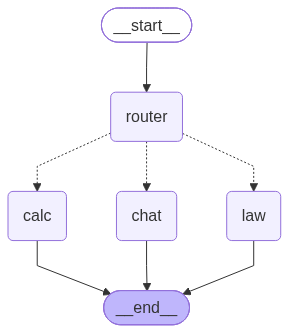

In [82]:
try:
    from IPython.display import Image, display
    display(Image(chatbot.get_graph().draw_mermaid_png()))
except Exception:
    print(chatbot.get_graph().draw_ascii())

**이 셀이 한 일**: 만든 챗봇 구조를 그림으로
확인합니다.

### 셀 16 — 완성된 챗봇 사용

In [83]:
def ask(question):
    result = chatbot.invoke({"question": question,
                             "kind": "", "answer": ""})
    badge = {"calc": "🧮 계산봇", "law": "📖 법령봇",
             "chat": "💬 상담봇"}.get(result["kind"], "🤖")
    print(f"🙋 {question}")
    print(f"{badge}: {result['answer']}\n")

# 4종 질문 — 라우터가 알아서 분기
ask("안녕하세요, 무엇을 도와주나요?")
ask("과세표준 3000만원에 15% 세율이면 세금은?")
ask("기본공제는 1인당 얼마까지 인정되나요?")
ask("종합소득세 과세기간은 어떻게 정해지나요?")

🙋 안녕하세요, 무엇을 도와주나요?
💬 상담봇: 안녕하세요! 세무 관련 질문이나 상담이 필요하시면 언제든지 말씀해 주세요. 세금 계산이나 법령에 대한 질문은 '계산/법령 기능을 이용해 주세요'라고 안내해 드립니다.

🙋 과세표준 3000만원에 15% 세율이면 세금은?
🧮 계산봇: 과세표준이 3,000만원인 경우, 해당 금액은 다음과 같은 구간에 해당합니다:

- 1,400만원 이하: 과세표준의 6%
- 1,400만원 초과 5,000만원 이하: 84만원 + (1,400만원을 초과하는 금액의 15%)

따라서, 3,000만원에 대한 세금을 계산하기 위해 단계별로 나누어 계산하겠습니다.

1. **1,400만원 이하 부분의 세금 계산:**
   - 1,400만원 × 6% = 84만원

2. **1,400만원 초과 부분의 세금 계산:**
   - 3,000만원 - 1,400만원 = 1,600만원 (1,400만원 초과 금액)
   - 1,600만원 × 15% = 240만원

3. **총 세금 계산:**
   - 84만원 (1,400만원 이하 부분) + 240만원 (1,400만원 초과 부분) = 324만원

따라서, 과세표준 3,000만원에 대한 최종 산출세액은 **324만원**입니다.
(소득세법 제55조 세율표 근거 · 참고용)

🙋 기본공제는 1인당 얼마까지 인정되나요?
📖 법령봇: 기본공제는 1인당 150만원까지 인정됩니다.

🙋 종합소득세 과세기간은 어떻게 정해지나요?
📖 법령봇: 자료에서 확인되지 않습니다.



**이 셀이 한 일**: 완성된 멀티 챗봇을 사용했습니다.
질문마다 다른 봇이 답하는 게 보입니다.

# 7️⃣ 단계 — 기본 vs 완성 비교

처음 만든 단순 RAG와 완성된 멀티 챗봇을 같은 질문으로
비교합니다. (방법론 교안의 '⑦ 평가' 단계)

### 셀 17 — 나란히 비교

In [84]:
test_questions = [
    "안녕하세요!",
    "과세표준 1400만원에 6% 세율이면 세금은?",
    "기본공제 금액을 알려주세요",
]

for q in test_questions:
    print(f"🙋 {q}")
    # ① 단순 RAG (무조건 검색)
    print(f"  ① 단순 RAG : {simple_rag(q)[:70]}")
    # ② 멀티 챗봇 (라우팅)
    r = chatbot.invoke({"question": q, "kind": "", "answer": ""})
    print(f"  ② 멀티 챗봇: [{r['kind']}] {r['answer'][:70]}")
    print()

print("=" * 58)
print("""
👀 무엇이 달라졌나
┌─────────┬───────────────────┬───────────────────────┐
│ 질문    │ 단순 RAG          │ 멀티 챗봇             │
├─────────┼───────────────────┼───────────────────────┤
│ 잡담    │ 엉뚱한 조문 검색  │ 상담봇이 자연 응대    │
│ 계산    │ LLM 환각 위험     │ 계산봇이 코드로 정확  │
│ 법령    │ RAG 답변 (양호)   │ 법령봇 RAG (동일)     │
└─────────┴───────────────────┴───────────────────────┘
핵심: 단순 RAG는 '한 길', 멀티 챗봇은 '질문별 최적 경로'
""")

🙋 안녕하세요!
  ① 단순 RAG : 자료에서 확인되지 않습니다.
  ② 멀티 챗봇: [chat] 안녕하세요! 무엇을 도와드릴까요?

🙋 과세표준 1400만원에 6% 세율이면 세금은?
  ① 단순 RAG : 과세표준 1,400만원에 6% 세율을 적용하면 세금은 84만원입니다.
  ② 멀티 챗봇: [calc] 과세표준이 1,400만원 이하인 경우, 세율은 과세표준의 6%입니다. 따라서 계산 과정을 단계별로 보여드리겠습니다.

1. *

🙋 기본공제 금액을 알려주세요
  ① 단순 RAG : 자료에서 확인되지 않습니다.
  ② 멀티 챗봇: [chat] 기본공제 금액은 개인의 상황에 따라 다를 수 있으니, 정확한 금액을 확인하시려면 계산/법령 기능을 이용해 주세요.


👀 무엇이 달라졌나
┌─────────┬───────────────────┬───────────────────────┐
│ 질문    │ 단순 RAG          │ 멀티 챗봇             │
├─────────┼───────────────────┼───────────────────────┤
│ 잡담    │ 엉뚱한 조문 검색  │ 상담봇이 자연 응대    │
│ 계산    │ LLM 환각 위험     │ 계산봇이 코드로 정확  │
│ 법령    │ RAG 답변 (양호)   │ 법령봇 RAG (동일)     │
└─────────┴───────────────────┴───────────────────────┘
핵심: 단순 RAG는 '한 길', 멀티 챗봇은 '질문별 최적 경로'



**이 셀이 한 일**: 단순 RAG와 멀티 챗봇을 같은
질문으로 비교했습니다. 구조의 차이가 한눈에 보입니다.

# 8️⃣ 단계 — Gradio 채팅 UI (외부 공유용)

> 지금까지 만든 멀티 챗봇(`chatbot`)을 **웹 채팅 화면**으로
> 만듭니다. 링크 하나로 외부에 공유할 수 있습니다.

```
 [터미널에서 print]          [Gradio 채팅 UI]
 ask("질문")                 웹 채팅창 + 공유 링크
 → 텍스트 출력               → 누구나 브라우저로 대화
```

**핵심**: 새 챗봇을 또 만드는 게 아닙니다. 6단계에서
완성한 `chatbot`(LangGraph)을 **그대로** 채팅 UI에
연결만 합니다. 질문 종류(일반/세무/계산)에 따라 답하는
봇이 화면에 표시됩니다.

### 셀 18 — Gradio 설치

In [85]:
!pip install -q gradio
print("✅ Gradio 설치 완료")

✅ Gradio 설치 완료



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


**이 셀이 한 일**: 채팅 UI 라이브러리 Gradio를
설치했습니다.

### 셀 19 — 챗봇을 Gradio에 연결하는 함수

Gradio `ChatInterface`는 `(message, history)` 를 받아
답 문자열을 돌려주는 함수 하나만 있으면 됩니다.
기존 `chatbot`(LangGraph)을 그대로 호출합니다.

In [86]:
# ✍️ [빈칸 채우기] Gradio가 부를 함수 — chatbot 재사용
def chat_fn(message, history):
    # chatbot 호출 — 힌트: chatbot.invoke({"question":message,
    #   "kind":"", "answer":""})
    result = chatbot.invoke({"question": message,
                           "kind": "", "answer": ""})
    label = {"calc": "🧮 계산",
             "law":  "📖 세무",
             "chat": "💬 일반"}.get(result["kind"], "🤖")
    return f"[{label}] {result['answer']}"

print(chat_fn("기본공제는 얼마인가요?", []))
print(chat_fn("과세표준 2000만원 6% 세금?", []))
print(chat_fn("안녕하세요", []))

[📖 세무] 자료에서 확인되지 않습니다.
[🧮 계산] 과세표준이 2,000만원인 경우, 종합소득세 세율표에 따라 계산해 보겠습니다.

1. **과세표준 확인**: 2,000만원

2. **적용되는 세율 구간 확인**:
   - 1,400만원 이하: 6%
   - 1,400만원 초과 5,000만원 이하: 84만원 + (1,400만원을 초과하는 금액의 15%)

   2,000만원은 1,400만원을 초과하므로 두 번째 구간에 해당합니다.

3. **세액 계산**:
   - 1,400만원에 대한 세액: 84만원
   - 1,400만원을 초과하는 금액: 2,000만원 - 1,400만원 = 600만원
   - 초과 금액에 대한 세액: 600만원 × 15% = 90만원

4. **총 세액 계산**:
   - 총 세액 = 84만원 + 90만원 = 174만원

따라서, 과세표준 2,000만원에 대한 최종 산출세액은 **174만원**입니다.
(소득세법 제55조 세율표 근거 · 참고용)
[💬 일반] 안녕하세요! 위니브 세무 상담 챗봇입니다. 어떤 도움이 필요하신가요?


**이 셀이 한 일**: Gradio가 부를 함수를
만들었습니다. 질문을 `chatbot`에 넣고, 답한 봇 종류
(🧮계산 / 📖세무 / 💬일반)를 배지로 붙여 돌려줍니다.

> 💡 세 테스트가 각각 [📖세무] [🧮계산] [💬일반] 로
> 다르게 나오면 라우터가 잘 동작하는 것입니다.

### 셀 20 — 채팅 UI 띄우기 (기본 버전)

`ChatInterface` 하나로 채팅창 + 예시 + 공유 링크가
한 번에 만들어집니다.

In [ ]:
# ✍️ [빈칸 채우기] 채팅 UI + 외부 공유
import gradio as gr

# (1) ChatInterface — 힌트: gr.ChatInterface(fn=chat_fn, ...)
demo = gr.____(
    fn=chat_fn,
    title="🏦 위니브 세무 챗봇",
    description="소득세법 안내 · 세금 계산 · 일반 상담",
    examples=[
        "안녕하세요, 무엇을 도와주나요?",
        "기본공제는 1인당 얼마인가요?",
        "과세표준 3000만원에 15% 세율이면 세금은?",
        "종합소득세 과세기간은 어떻게 되나요?",
    ],
)

# (2) 외부 공유 — 힌트: demo.launch(share=True)
demo.____(share=True)

**이 셀이 한 일**: 웹 채팅 UI를 띄웠습니다.

> 🌐 **외부 공유**: `share=True` 라서 `https://xxxx.
> gradio.live` 공개 링크가 생깁니다. 이 링크를 보내면
> 누구나 브라우저에서 이 챗봇과 대화할 수 있습니다
> (링크는 72시간 유효).
>
> 💬 예시 버튼을 누르면 일반/세무/계산 질문이 각각
> 어떤 담당(배지)에게 가는지 바로 확인됩니다.

### 셀 21 — (선택) UI 종료

다 쓴 뒤 리소스를 정리하려면 실행합니다.

In [ ]:
demo.close()
print("✅ 채팅 UI 종료 (다시 쓰려면 셀 20 재실행)")

**이 셀이 한 일**: 채팅 UI를 종료했습니다.
(공유 링크도 닫힙니다)

---
### 📌 8단계 정리 — Gradio로 무엇이 달라졌나

```
 [전]  코드 아는 사람만, Colab 셀에서 ask("...")
 [후]  누구나, 브라우저 채팅창에서 자연스럽게 대화
        + 일반/세무/계산 담당이 자동 분기
        + 공유 링크로 외부 배포
```

| 항목 | 내용 |
|------|------|
| 재사용 | 6단계 `chatbot`(LangGraph) 그대로 |
| 추가한 것 | `chat_fn` 1개 + `ChatInterface` 1줄 |
| 채팅 분기 | 💬일반 / 📖세무 / 🧮계산 (라우터가 자동) |
| 외부 공유 | `share=True` → 공개 링크 |

> 핵심: 챗봇 로직은 안 바꿨습니다. **UI 껍데기만**
> 씌워 "코드 모르는 사람도 쓰는 챗봇"이 됐습니다.
> 이게 실서비스로 가는 첫걸음입니다.

---
# 🎓 정리 —

```
 1️⃣ 준비 → 2️⃣ PDF·분할 → 3️⃣ 검색준비 → 4️⃣ 단순RAG
                                            │
 7️⃣ 비교 ← 6️⃣ LangGraph ← 5️⃣ 한계측정·3봇 ┘
```

| 단계 | 
|------|---------------|
| PDF·조문 분할 (2단계) | 텍스트 추출·청킹  |
| 임베딩·FAISS (3단계) | 벡터 검색  |
| 단순 RAG (4단계) | 검색→생성  |
| 한계 측정 (5단계) | 평가 관점 ) |
| 3개 봇 (5단계) | 거짓말 방지·도구  |
| LangGraph (6단계) | 그래프·조건부 분기  |
| 비교 (7단계) | 회귀 비교  |

## 한 문장 요약

> **챗봇은 한 번에 크게 만들지 않는다.** 단순 RAG로
> 시작 → 한계를 직접 측정 → 질문 종류별 봇으로 나누고
> → LangGraph로 연결 → 기본과 비교해 효과 확인.


## 🤔 더 해보기 (선택)

1. 셀 6의 조문 분할을 그대로 두고, 검색 `k`를 5로
   늘리면 답이 더 좋아질까요? (3단계 수정)
2. 라우터가 틀리게 분류하는 질문을 찾아보세요.
   (애매한 질문일수록 라우터가 헷갈립니다)
3. 봇을 하나 더 추가해보세요. 예: '서식 안내봇'.
   (노드 1개 + 라우터 분류 1개 추가 = 끝)
4. 심화 도전: 법령봇에 하이브리드 검색(BM25+벡터)을
   적용하면 "제59조의4" 같은 정확 조문번호를 더 잘
   찾습니다 (심화2 참고).

> ⚠️ 본 실습은 RAG·챗봇 학습용입니다. 실제 세무 판단은
> 세무사·국세청을 통해 확인하세요.

>  배운 RAG·LangGraph·라우팅· 도구를 실제 소득세법 문서로 통합해 멀티 챗봇을
>  완성했습니다. 🎉


---
## 🎓 다 채웠다면

```
 빈칸 24개를 모두 채우고 처음부터 끝까지 실행했다면:
 ✅ 소득세법 PDF → 조문 분할 → 벡터DB
 ✅ 세율표 이미지 → 멀티모달 복원
 ✅ 단순 RAG → 3개 봇 → LangGraph 라우팅
 ✅ Gradio 채팅 UI + 외부 공유 링크
 = 부트캠프 전 과정을 손으로 구축 완료! 🎉
```

**자가 점검**
- [ ] 계산봇이 과세표준 2000만원 → 174만원? (120만 아님)
- [ ] "과세표준 어떻게 돼?"가 📖세무로 분류?
- [ ] Gradio 공유 링크가 생성됨?

**정답 확인**: `..._Gradio_v4.ipynb` (완성본 = 강사용 정답지)
**원리 복습**: `멀티챗봇_구축_방법론과_프로세스_교안.md`

> 빈칸을 스스로 채웠다면, 이제 이 구조를 **다른 문서로도**
> 만들 수 있습니다. 
---